# Original agent workflow and later replay walkthrough

Executed imports and source inspection. No agents, incidents, provider judgments or new study analyses are run.

In [1]:
from pathlib import Path
import ast,importlib.util,inspect,sys
import pandas as pd
from IPython.display import display,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'METHOD_SOURCE_MAP.json').is_file())
def load_source(name,path):
    spec=importlib.util.spec_from_file_location(name,path)
    module=importlib.util.module_from_spec(spec);sys.modules[name]=module;spec.loader.exec_module(module)
    return module
def show_function(path,name):
    text=path.read_text();n=next(n for n in ast.parse(text).body if isinstance(n,(ast.FunctionDef,ast.ClassDef)) and n.name==name)
    print(ast.get_source_segment(text,n))

P=ROOT/'code/agents'
agent=load_source('public_archived_simulation',P/'archived_simulation.py')
personas=load_source('public_persona_mapping',P/'persona_mapping.py')
replay=load_source('public_replay_judgment',P/'replay_judgment.py')

## 1. Actual archived non-smoke settings
These are hand-specified simulation parameters, distinct from learned model weights. No persona records are included.

In [2]:
display(pd.DataFrame([{'setting':k,'value':str(v)} for k,v in agent.CFG.items()]))
print('Original noticing coefficients:',agent.NOTICE_PARAMS)

,setting,value
0,N_AGENTS,30
1,N_DAYS,21
2,N_POI_PER_DAY,3
3,N_ZIPS,None
4,SEEDS,"[42, 43, 44]"
5,SEEDS_SECONDARY,[42]
6,ARMS,"['observed', 'swap']"
7,ENGINES,"['primary', 'legacy', 'attach0']"
8,VISUAL_PULL,1.0
9,VISUAL_PULL_GRID,"[0.5, 1.5]"


Original noticing coefficients: {'base': (0.1, 0.45, 0.25, 0.15, 0.3), 'lenient': (0.2, 0.45, 0.25, 0.15, 0.2), 'strict': (0.05, 0.4, 0.2, 0.1, 0.4)}


## 2. Original persona mapping and place choice
The original transformation uses caller-provided questionnaire fields. This notebook displays the function without supplying responses.

In [3]:
print(inspect.getsource(personas.build_persona_pool))
print(inspect.getsource(agent.day_state))
print(inspect.getsource(agent.choose_pois))

def build_persona_pool(G):

    def _01v(v, scale=None):
        v = pd.to_numeric(v, errors='coerce')
        if scale is not None:
            v = (v - scale[0]) / (scale[1] - scale[0])
        return v.clip(0, 1)

    def uni(col_wp, col_hwb, scale_hwb=(1, 5)):
        hv = _01v(G.get(col_hwb), scale_hwb) if col_hwb and col_hwb in G else pd.Series(np.nan, index=G.index)
        if col_wp and col_wp in G:
            wv = pd.to_numeric(G[col_wp], errors='coerce')
            wv = wv.mask(wv.isin([1, 2]), (wv == 1).astype(float)).clip(0, 1)
        else:
            wv = pd.Series(np.nan, index=G.index)
        return hv.fillna(wv)
    civ = uni(None, 'HWB10')
    pride = uni(None, 'HWB22')
    sat = uni('WP83', 'HWB9')
    learn = uni('WP65', 'HWB2')
    safe = uni('WP113', 'HWB23')
    purp = uni(None, 'HWB1')
    sh = pd.to_numeric(G.get('M19'), errors='coerce').clip(0, 12)
    GPOOL = pd.DataFrame(dict(zip=G['ZIPCODE'].astype(str).str.zfill(5), respondent_id=np.arange(len(G)), pro

## 3. Full original single-area runner
The sequence is place choice → visit/memory update → incident → stochastic noticing → older audit/report layer. This historical layer is separate from later replay outcomes.

In [4]:
print(inspect.getsource(agent.p_notice))
print(inspect.getsource(agent.run_one))

def p_notice(att,mine,sal,busy,variant='base'):
    b,wa,wm,ws,wb=NOTICE_PARAMS[variant]
    return float(np.clip(b+wa*att+wm*mine+ws*sal-wb*busy,.02,.95))

def run_one(zc,seed,arm,engine,vp=None,notice_variant=None):
    vp=CFG['VISUAL_PULL'] if vp is None else vp; nv=CFG['NOTICE_VARIANT'] if notice_variant is None else notice_variant  # 0.0 falsy 버그 수정
    tag=f"{zc}_s{seed}_{arm}_{engine}_vp{vp}_{nv}_{CFG['PERSONA_SOURCE']}"
    rd=RUNS/tag; rd.mkdir(parents=True,exist_ok=True); fs=rd/'summary.json'
    if CFG['RESUME'] and fs.exists(): return json.loads(fs.read_text())
    rng=np.random.default_rng(seed*100003+int(zc)+hash((arm,engine,vp,nv))%9973)
    poi_df=poi_vis[poi_vis['zip']==zc].copy().reset_index(drop=True)
    v=pd.to_numeric(poi_df.visual_invitation_actual,errors='coerce').fillna(.5)
    poi_df['vis_used']=(v.min()+v.max()-v) if arm=='swap' else v
    agents=make_agents(zc,poi_df,CFG['N_AGENTS'],rng)
    alpha=0.0 if engine=='attach0' else CFG['MINENESS_ALPHA']
    pend=

## 4. Actual later replay prompts
The later prompts receive history and problem context, excluding numeric ownership memory, visual score and place identity. These are original templates, not raw requests or new judgments.

In [5]:
print(inspect.getsource(replay.prompt_task))
print(inspect.getsource(replay.prompt_ownership))
print('Actual task framing:')
display(pd.DataFrame([{'task':k,'scenario':str(replay.TASK_LINE[k]),'question_action':v} for k,v in replay.TASK_ASK.items()]))

def prompt_task(task, typ, eff_b, busy_b, fam=None, kprior=None, unspec=False):
    """fam=None -> no history line (the original 'hidden' variant, kept for the record);
       unspec=True -> alternative control: a same-form line saying the history is not specified;
       fam=1, kprior=0 -> structurally matched first-visit control; otherwise the actual history."""
    lines = ["You are simulating one resident of a large U.S. city.", "",
             f"The resident: they {eff_b}. {busy_b}", "",
             f"Walking through the neighbourhood, they notice {PROBLEM[typ]}."]
    line = TASK_LINE[task]
    if task == 'steward':
        line = (f"Dealing with it themselves would take about fifteen minutes: {STEWARD_ACTION[typ]}, perhaps with help from a passer-by "
                "or a neighbour. They can stop and take care of it now, or keep walking and leave it.")
    if line: lines.append(line)
    if unspec: lines.append(UNSPEC_LINE)
    elif fam is not None: lines.append(f"{visit_phra

,task,scenario,question_action
0,report,Reporting it to the city's 311 service takes a...,stop and file the report now
1,dosomething,None,"do something about it today, such as reporting..."
2,steward,None,stop and take care of it themselves
3,signup,A neighbourhood group is organising a two-hour...,sign up today
4,gather,Some residents are getting together this week ...,join them


## 5. Original paired replay processing
The entire original provider/cache program is available in `replay_judgment.py`; this cell only displays downstream functions.

In [6]:
show_function(P/'replay_analysis.py','load_results')
show_function(P/'replay_analysis.py','history_effects')

def load_results(path):
    r = pd.read_csv(path, low_memory=False)
    r['swap'] = (r.arm == 'swap').astype(int)
    r['public'] = (r.kind == 'public').astype(int)
    for c in ['shown', 'first', 'unspec']:
        if f'signup_{c}' in r and f'gather_{c}' in r:
            r[f'civic_action_{c}'] = r[[f'signup_{c}', f'gather_{c}']].mean(axis=1)
    if 'k_signup_shown' in r:
        r['k_civic_action_shown'] = r['k_signup_shown'] + '|' + r['k_gather_shown']
    if 'civic_action_shown_sd' not in r and 'signup_shown_sd' in r:
        r['civic_action_shown_sd'] = r[['signup_shown_sd', 'gather_shown_sd']].mean(axis=1)
    return r
def history_effects(r, control='first'):
    rows, curves = [], {}
    for oc in OUTCOMES:
        d = _pub(r, oc, control)
        h = d[d.has_history]
        m = fit(d, 'delta', ['fam', 'k_prior'])
        hi = d[d.fam >= 6]
        rows.append(dict(outcome=oc, label=LABEL[oc], counterpart=COUNTERPART[oc], n=len(d),
                         control_mean=100 * d[

## 6. Existing saved aggregate figure
The displayed values are archived model-judged shares, not new outputs or observed human actions.

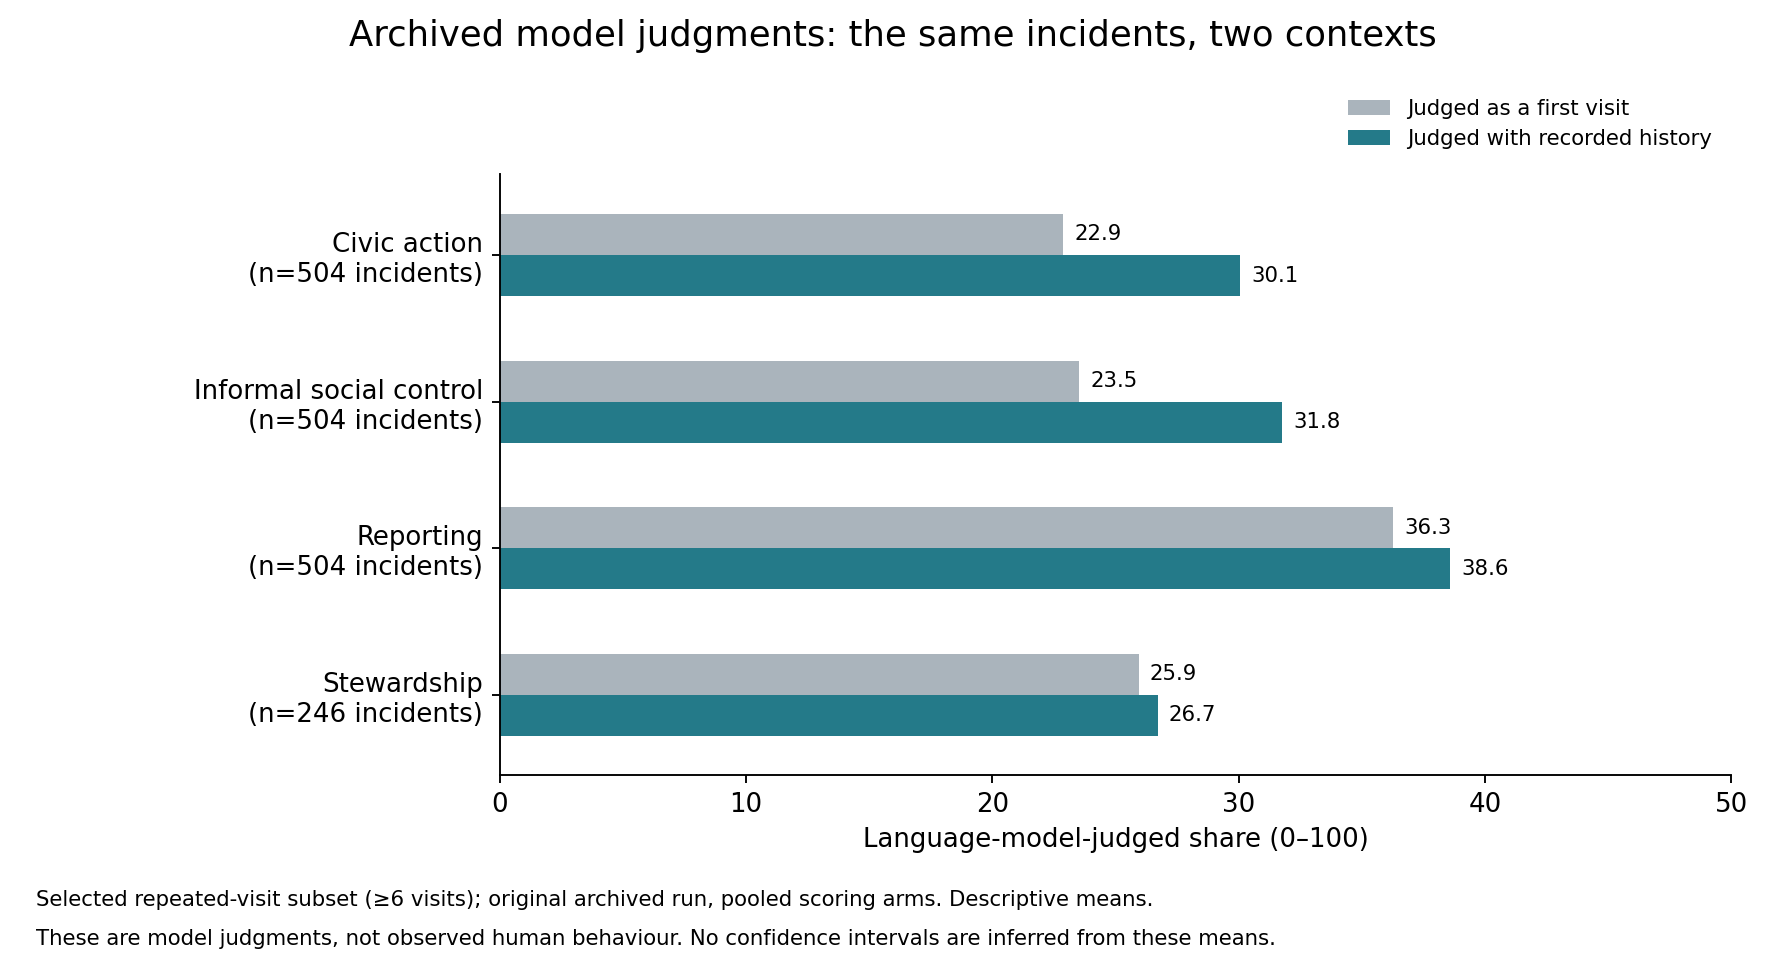

In [7]:
display(Image(filename=str(ROOT/'figures/02_saved_archived_replay.png')))

See `METHODS_AND_INPUTS.md` for the preserved older fallback behavior, process-dependent hash seeding and full input contracts. The original survey and geographic results remain in the separate selected-results notebook.